In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score

original_df = pd.read_csv("Country-data.csv")
df=original_df.copy()
X=df.drop("country", axis=1)

rows = df.shape[0]
cols = df.shape[1]

param_grid = {
    "kmeans__n_clusters": range(2,11)
}

def silhouette(model, X):
    X_scaled = model["scaler"].transform(X)
    return silhouette_score(X_scaled, model.predict(X))

def inertia(model, X):
    return model.score(X)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans( random_state=42, n_init=10))
])
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {
    "kmeans__n_clusters": range(2,11)}
grid = GridSearchCV(pipeline, param_grid,
                    scoring={"silhouette": silhouette,
                             "inertia": inertia}, refit="silhouette", cv=kf)
grid.fit(X)

grid.best_params_

{'kmeans__n_clusters': 2}

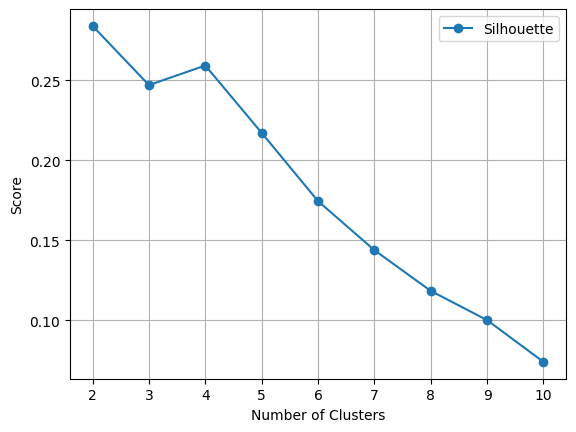

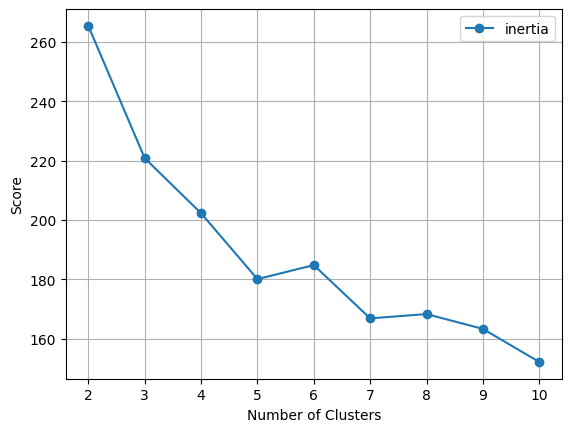

In [9]:
plt.plot(grid.cv_results_["param_kmeans__n_clusters"], grid.cv_results_["mean_test_silhouette"], label="Silhouette", marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()


plt.plot(grid.cv_results_["param_kmeans__n_clusters"], -grid.cv_results_["mean_test_inertia"], label="inertia", marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

In [10]:

param_grid = {
    "kmeans__n_clusters": 3
}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=3,random_state=42, n_init=10))
])
pipeline.fit(X)
labels = pipeline.predict(X)
df["clusters"] = labels
df.groupby("clusters").count()
cluster_names = {
    0: " Economically Advanced Countries",
    1: "High Aid Priority Countries",
    2: "Developing / Moderate Aid Priority Countries"
}
df["clusters"] = df["clusters"].map(cluster_names)
df

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,clusters
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,High Aid Priority Countries
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,Developing / Moderate Aid Priority Countries
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,Developing / Moderate Aid Priority Countries
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,High Aid Priority Countries
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,Developing / Moderate Aid Priority Countries
...,...,...,...,...,...,...,...,...,...,...,...
162,Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970,Developing / Moderate Aid Priority Countries
163,Venezuela,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500,Developing / Moderate Aid Priority Countries
164,Vietnam,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310,Developing / Moderate Aid Priority Countries
165,Yemen,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310,High Aid Priority Countries


In [11]:
df.groupby("clusters")[
    X.columns
].mean().round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
clusters,,,,,,,,,
Economically Advanced Countries,5.00,58.74,8.81,51.49,45672.22,2.67,80.13,1.75,42494.44
Developing / Moderate Aid Priority Countries,21.93,40.24,6.20,47.47,12305.60,7.60,72.81,2.31,6486.45
High Aid Priority Countries,92.96,29.15,6.39,42.32,3942.40,12.02,59.19,5.01,1922.38


In [12]:
df["clusters"].value_counts()

,count
clusters,
Developing / Moderate Aid Priority Countries,84
High Aid Priority Countries,47
Economically Advanced Countries,36


In [13]:
import plotly.express as px

fig = px.choropleth(
    df,
    locations="country",
    locationmode="country names",
    color="clusters",
    hover_name="country",
    hover_data=["income", "gdpp", "child_mort", "life_expec"],
    title="Global Country Clusters",
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.show()

In [14]:
cluster_avg = df.groupby("clusters")[X.columns].mean()

country = input("Enter country name: ")

selected = df[df["country"] == country]
selected

Enter country name: Pakistan


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,clusters
116,Pakistan,92.1,13.5,2.2,19.4,4280,10.9,65.3,3.85,1040,High Aid Priority Countries


In [15]:
cluster = selected["clusters"].values[0]

country_data = selected[X.columns].iloc[0]

average_data = cluster_avg.loc[cluster]

print(average_data)

child_mort      92.961702
exports         29.151277
health           6.388511
imports         42.323404
income        3942.404255
inflation       12.019681
life_expec      59.187234
total_fer        5.008085
gdpp          1922.382979
Name: High Aid Priority Countries, dtype: float64


In [16]:
comparison = pd.DataFrame({
    "Country": country_data,
    "Cluster Average": average_data
})

display(comparison)

,Country,Cluster Average
child_mort,92.10,92.961702
exports,13.50,29.151277
health,2.20,6.388511
imports,19.40,42.323404
income,4280.00,3942.404255
inflation,10.90,12.019681
life_expec,65.30,59.187234
total_fer,3.85,5.008085
gdpp,1040.00,1922.382979


/tmp/ipykernel_1201/1114270315.py:13: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



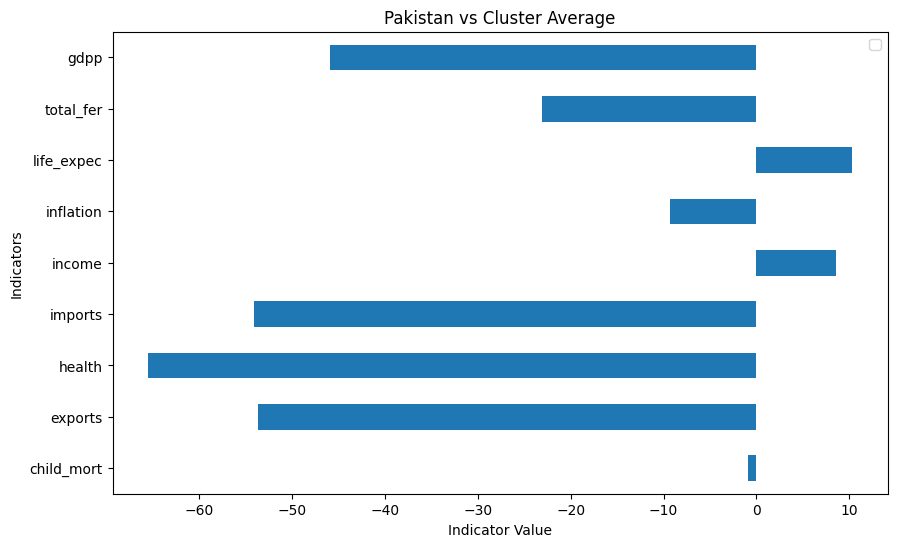

In [17]:
percentage_difference = (
    (country_data - average_data) / average_data
) * 100

percentage_difference.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title(f"{country} vs Cluster Average")
plt.xlabel("Indicator Value")
plt.ylabel("Indicators")
plt.legend()
plt.show()

In [18]:
import ipywidgets as widgets
from IPython.display import display, clear_output
country_dropdown = widgets.Dropdown(
    options=sorted(df["country"].unique()),
    description="Country:",
    value="Pakistan"
)

display(country_dropdown)
def show_country(country):

    selected = df[df["country"] == country]

    cluster = selected["clusters"].iloc[0]

    country_data = selected[X.columns].iloc[0]
    average_data = cluster_avg.loc[cluster]

    comparison = pd.DataFrame({
        "Country": country_data,
        "Cluster Average": average_data
    })

    display(comparison)

    comparison.plot(
        kind="barh",
        figsize=(10, 6)
    )

    plt.title(f"{country} vs Cluster Average")
    plt.show()
output = widgets.interactive_output(
    show_country,
    {"country": country_dropdown}
)

display(output)

Dropdown(description='Country:', index=116, options=('Afghanistan', 'Albania', 'Algeria', 'Angola', 'Antigua a…

Output()

In [19]:
df.to_csv("Country-data-clustered.csv", index=False)